# Wrangling dan EDA

In [22]:
import pandas as pd
from neo4j import GraphDatabase

# load data
df = pd.read_csv('data/events.csv')
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

# periode dataset
P1_start, P1_end = '2015-05-17', '2015-06-21'
P2_start, P2_end = '2015-06-17', '2015-07-21'

# konversi ke unix timestamp 
p1_start_ts = int(pd.to_datetime(P1_start).timestamp() * 1000)
p1_end_ts = int(pd.to_datetime(P1_end + ' 23:59:59').timestamp() * 1000)

p2_start_ts = int(pd.to_datetime(P2_start).timestamp() * 1000)
p2_end_ts = int(pd.to_datetime(P2_end + ' 23:59:59').timestamp() * 1000)

# filter dan simpan cvs
df_p1 = df[(df['datetime'] >= P1_start) & (df['datetime'] <= P1_end)]
df_p2 = df[(df['datetime'] >= P2_start) & (df['datetime'] <= P2_end)]

df_p1.to_csv('data/events_P1_train.csv', index=False)
df_p2.to_csv('data/events_P2_test.csv', index=False)

print(f"Data P1: {len(df_p1)} baris | Data P2: {len(df_p2)} baris")

Data P1: 723852 baris | Data P2: 719384 baris


In [23]:
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password123")

driver = GraphDatabase.driver(URI, auth=AUTH)

# query cypher langsung panggil variabel p1_start_ts & p1_end_ts
cypher_rels_p1 = f"""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= {p1_start_ts} AND r.timestamp <= {p1_end_ts}
RETURN type(r) AS Jenis_Hubungan, count(r) AS Jumlah_Hubungan
"""

cypher_nodes_p1 = f"""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= {p1_start_ts} AND r.timestamp <= {p1_end_ts}
RETURN count(DISTINCT v) AS Visitor_Aktif_P1, count(DISTINCT i) AS Item_Aktif_P1
"""

with driver.session() as session:
    df_rels_p1 = pd.DataFrame([r.data() for r in session.run(cypher_rels_p1)])
    df_nodes_p1 = pd.DataFrame([r.data() for r in session.run(cypher_nodes_p1)])

driver.close()

print("Jumlah Simpul Unik (Periode P1)")
print(df_nodes_p1)
print("\nKomposisi Hubungan (Periode P1)")
print(df_rels_p1)

Jumlah Simpul Unik (Periode P1)
   Visitor_Aktif_P1  Item_Aktif_P1
0            382258         129262

Komposisi Hubungan (Periode P1)
  Jenis_Hubungan  Jumlah_Hubungan
0         VIEWED           715697
1  ADDED_TO_CART            17955
2         BOUGHT             5832


CYPHER SQL yang digunakan

MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $p1_start_ts AND r.timestamp <= $p1_end_ts
RETURN type(r) AS Jenis_Hubungan, count(r) AS Jumlah_Hubungan
- MATCH (v=visitor)-[r]->(i:item): mengidentifikasi pola graf yang menghubungkan simpul visitor ke simpul item melalui relasi r
- WHERE r.timestamp >= Memfilter relasi agar hanya menghitung transaksi/interaksi yang terjadi pada rentang waktu Periode P1.
- type(r): Fungsi untuk mengambil jenis nodes dari relasi
- count(r): menghitung total kemunculan jenis node


MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $p1_start_ts AND r.timestamp <= $p1_end_ts
RETURN count(DISTINCT v) AS Visitor_Aktif_P1, count(DISTINCT i) AS Item_Aktif_P1
- count(DISTINCT v): menghitung jumlah entitas visitor unik yang melakukan minimal satu interaksi pada periode P1
- count(DISTINC i): menghitung jumlah entitas item unik yang pernah diakses/diinteraksi pada periode P1


In [24]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# query cypher untuk mengambil interaksi di periode P1
cypher_vsm = f"""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= {p1_start_ts} AND r.timestamp <= {p1_end_ts}
RETURN v.visitorId AS visitor_id, i.itemId AS item_id, count(r) AS weight
"""

with driver.session() as session:
    result = session.run(cypher_vsm)
    data_vsm = [record.data() for record in result]

df_vsm_raw = pd.DataFrame(data_vsm)

# mapping ID ke index integer
unique_visitors = df_vsm_raw['visitor_id'].unique()
unique_items = df_vsm_raw['item_id'].unique()

visitor_to_idx = {v_id: idx for idx, v_id in enumerate(unique_visitors)}
item_to_idx = {i_id: idx for idx, i_id in enumerate(unique_items)}

# mapping balik untuk pencarian
idx_to_visitor = {idx: v_id for v_id, idx in visitor_to_idx.items()}
idx_to_item = {idx: i_id for i_id, idx in item_to_idx.items()}

# mapping kolom dataframe ke index integer
row_indices = df_vsm_raw['visitor_id'].map(visitor_to_idx).values
col_indices = df_vsm_raw['item_id'].map(item_to_idx).values
weights = df_vsm_raw['weight'].values

# 3. sparse matrix VSM 
vsm_sparse = csr_matrix((weights, (row_indices, col_indices)), 
                        shape=(len(unique_visitors), len(unique_items)))

print(f"Bentuk Matriks VSM Sparse (Visitor x Item): {vsm_sparse.shape}")
print(f"Jumlah elemen non-zero (interaksi nyata): {vsm_sparse.nnz}")

Bentuk Matriks VSM Sparse (Visitor x Item): (382258, 129262)
Jumlah elemen non-zero (interaksi nyata): 573315


KARAKTERISTIK VECTOR SPACE MODEL (VSM)
1. Dimensi Matriks (Shape): 382258 User x 129262 Item
2. Total Elemen Matriks: 49,411,433,596 sel
3. Elemen Terisi: 573,315 interaksi
4. Tingkat Kelangkaan: 99.9988% (Sparsity Rate)
5. Rata-rata Interaksi/User: 1.50 item
6. Max Interaksi oleh 1 User: 1128 item


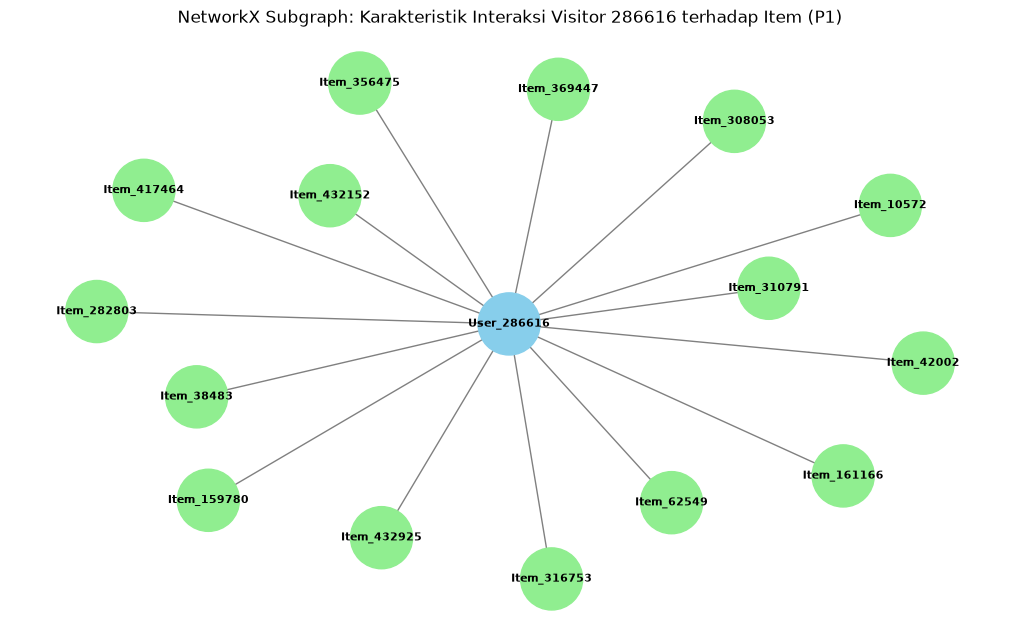

In [25]:
import matplotlib.pyplot as plt
import networkx as nx

# karakteristik VSM 
num_users, num_items = vsm_sparse.shape
nnz = vsm_sparse.nnz
sparsity = 100 * (1 - (nnz / (num_users * num_items)))

# derajat interaksi per user
user_degrees = np.diff(vsm_sparse.indptr)

print("KARAKTERISTIK VECTOR SPACE MODEL (VSM)")
print(f"1. Dimensi Matriks (Shape): {num_users} User x {num_items} Item")
print(f"2. Total Elemen Matriks: {num_users * num_items:,} sel")
print(f"3. Elemen Terisi: {nnz:,} interaksi")
print(f"4. Tingkat Kelangkaan: {sparsity:.4f}% (Sparsity Rate)")
print(f"5. Rata-rata Interaksi/User: {np.mean(user_degrees):.2f} item")
print(f"6. Max Interaksi oleh 1 User: {np.max(user_degrees)} item")

# plot subgraph dengan networkx (mengambil sampel user top interaksi)
# ambil 1 user yang punya interaksi terbanyak agar plotnya bagus & tidak berat
top_user_idx = np.argmax(user_degrees)
top_user_id = idx_to_visitor[top_user_idx]

# ambil item-item yang diakses oleh user tersebut
connected_item_indices = vsm_sparse[top_user_idx].indices
connected_item_ids = [idx_to_item[i] for i in connected_item_indices[:15]] # ambil max 15 item biar tidak menumpuk

# buat graf bipartite networkx
G = nx.Graph()
G.add_node(f"User_{top_user_id}", bipartite=0, color='skyblue')

for item_id in connected_item_ids:
    G.add_node(f"Item_{item_id}", bipartite=1, color='lightgreen')
    G.add_edge(f"User_{top_user_id}", f"Item_{item_id}")

# plot graf
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42)
colors = [G.nodes[n].get('color', 'gray') for n in G.nodes()]

nx.draw(G, pos, with_labels=True, node_color=colors, node_size=2000, font_size=8, font_weight='bold', edge_color='gray')
plt.title(f"NetworkX Subgraph: Karakteristik Interaksi Visitor {top_user_id} terhadap Item (P1)")
plt.show()

Analisis Visualisasi
- struktur graf= berbentuk bipartite graph lokal yang berpusat pada entitas simpul User_286616 yang terhubung dengan 15 entitas item
- interpretasi vektor= panjang garis edge dari User_286616 ke setiap item dari 15 item yang ada merepresentasikan bobot yang dimiliki

KARAKTERISTIK VECTOR SPACE MODEL (VSM) - ITEM BASED
1. Dimensi Matriks (Shape): 129262 Item x 382258 User
2. Total Elemen Matriks: 49,411,433,596 sel
3. Elemen Terisi: 573,315 interaksi
4. Tingkat Kelangkaan: 99.9988% (Sparsity Rate)
5. Rata-rata Visitor/Item: 4.44 visitor
6. Max Visitor oleh 1 Item: 1050 visitor


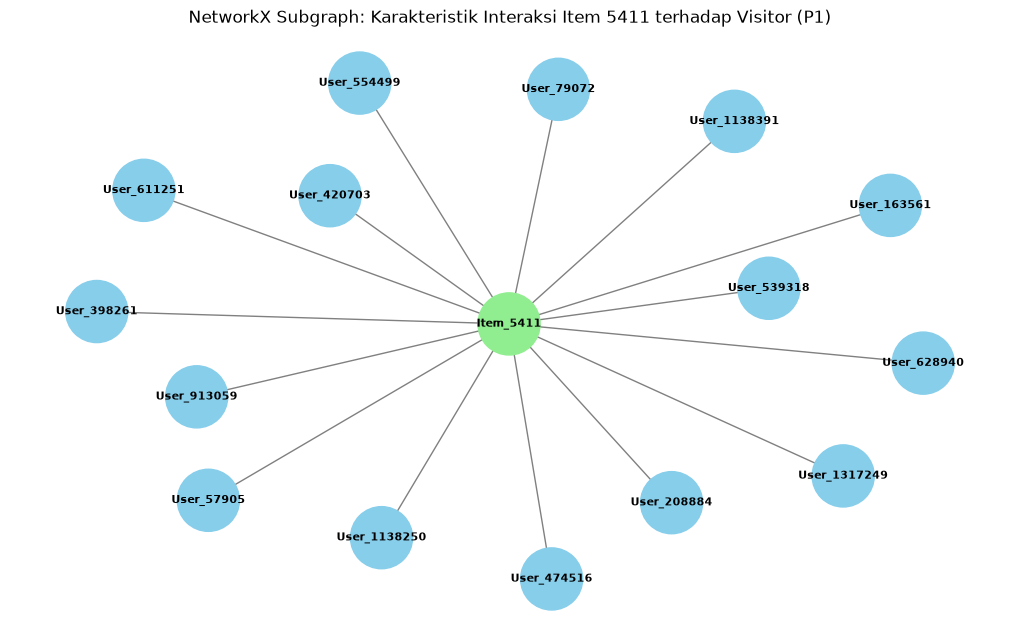

In [26]:
# transpose matriks VSM (untuk buat item-user Matrix)
# vsm_sparse sebelumnya: (user x item) -> vsm_item_sparse: (Item x User)
vsm_item_sparse = vsm_sparse.T.tocsr()

num_items_p5, num_users_p5 = vsm_item_sparse.shape
nnz_p5 = vsm_item_sparse.nnz
sparsity_p5 = 100 * (1 - (nnz_p5 / (num_items_p5 * num_users_p5)))

# hitung derajat interaksi per item (berapa banyak visitor yang mengakses item tersebut)
item_degrees = np.diff(vsm_item_sparse.indptr)

print("KARAKTERISTIK VECTOR SPACE MODEL (VSM) - ITEM BASED")
print(f"1. Dimensi Matriks (Shape): {num_items_p5} Item x {num_users_p5} User")
print(f"2. Total Elemen Matriks: {num_items_p5 * num_users_p5:,} sel")
print(f"3. Elemen Terisi: {nnz_p5:,} interaksi")
print(f"4. Tingkat Kelangkaan: {sparsity_p5:.4f}% (Sparsity Rate)")
print(f"5. Rata-rata Visitor/Item: {np.mean(item_degrees):.2f} visitor")
print(f"6. Max Visitor oleh 1 Item: {np.max(item_degrees)} visitor")

# plot subgraph networkx (sampel top item) 
# ambil 1 item dengan jumlah interaksi terbanyak
top_item_idx = np.argmax(item_degrees)
top_item_id = idx_to_item[top_item_idx]

# ambil visitor yang pernah mengakses item tersebut
connected_user_indices = vsm_item_sparse[top_item_idx].indices
connected_user_ids = [idx_to_visitor[u] for u in connected_user_indices[:15]] # Ambil max 15 visitor

# buat graf bipartite networkX
G_item = nx.Graph()
G_item.add_node(f"Item_{top_item_id}", bipartite=0, color='lightgreen')

for user_id in connected_user_ids:
    G_item.add_node(f"User_{user_id}", bipartite=1, color='skyblue')
    G_item.add_edge(f"Item_{top_item_id}", f"User_{user_id}")

# plot graf
plt.figure(figsize=(10, 6))
pos_item = nx.spring_layout(G_item, seed=42)
colors_item = [G_item.nodes[n].get('color', 'gray') for n in G_item.nodes()]

nx.draw(G_item, pos_item, with_labels=True, node_color=colors_item, node_size=2000, font_size=8, font_weight='bold', edge_color='gray')
plt.title(f"NetworkX Subgraph: Karakteristik Interaksi Item {top_item_id} terhadap Visitor (P1)")
plt.show()

Analisis Visualisasi
- struktur graf= berbentuk bipartite graph lokal yang berpusat pada entitas simpul Item_5411 yang terhubung dengan 15 entitas User
- interpretasi vektor= panjang garis edge dari Item_5411 ke setiap User dari 15 User yang ada merepresentasikan bobot yang dimiliki

Soal 2.1 poin 4 dan 5

Uraian Karakteristik VSM

Dimensi
- bentuk matriks VSM Sparse (Visitor x Item): (382258, 129262)
- total elemen matrika= 49,411,433,596 sel

Sparsity
- jumlah elemen non zero (interaksi nyata)= 573,315 interaksi 
- tingkat kelangkaan= 99.9988% yang artinya dimana satu visitor rata-rata hanya mengakses sejumlah kecil item dari total puluhan ribu katalog yang ada

Distribusi Komposisi Interaksi
- VIEWED= 715697 interaksi (96.78%) visitor melihat produk
- ADD_TO_CART= 17955 interaksi (2.43%) visitor menambahkan produk ke keranjang
- BOUGHT= 5832 interaksi (0.79%) visitor membeli produk

Perbandingan data 
- User-Based VSM= Memiliki 382258 vektor baris (User) dengan 129262 dimensi (Item). Rata-rata interaksi per user sangat sedikit (sekitar 1.50 item) dan Max Interaksi oleh 1 User adalah 1128 item
- Item-Based VSM: Memiliki 129262 vektor baris (Item) dengan 382258 dimensi (User). Rata-rata interaksi per item adalah 4.44 visitor dan Max Visitor oleh 1 Item adalah 1050 visitor


Soal 2.1 poin 6

Uraikan proyeksi manakah yang lebih baik

Sisi Efisiensi Komputasi (Kompleksitas Algoritma)
- Item-Based VSM jauh lebih efisien karena jumlah baris yang perlu dihitung matriks similarity hanya 129262  dibandingkan dengan User-Based yang mencapai 3x lebih banyak yakni 382258

Sisi Stabilitas Data & Efektivitas Rekomendasi
- Item-Based VSM lebih stabil karena Rata-rata keterhubungan Item-Based (4,44 visitor/item) lebih banyak informasi dibandingkan User-Based. Kebanyakan user di dataset P1 bersifat one-time visitor yang hanya melihat 1 atau 2 item lalu pergi. Hal ini membuat vektor User sangat rentan mengalami sparsity error saat dicari tetangga terdekatnya. selain itu pada dasarnya dalam dunia e-commerce, laman katalog relatif lebih statis dibandingkan jumlah user yang terus bertambah setiap saat

Kesimpulan

Lebih efisien dan efektif Item-Based VSM 


In [27]:
# tentukan item acuan dari item paling populer dari poin 5
target_item_id = 5411  # Bebas diganti ID lain kalau mau

# (a) cypher SQL: menghitung cosine similarity antar item di periode P1
# query ini mencari top-5 item yang paling mirip dengan target_item_id
cypher_top5_sim = f"""
MATCH (i1:Item {{itemId: {target_item_id}}})<-[r1]-(v:Visitor)-[r2]->(i2:Item)
WHERE r1.timestamp >= {p1_start_ts} AND r1.timestamp <= {p1_end_ts}
  AND r2.timestamp >= {p1_start_ts} AND r2.timestamp <= {p1_end_ts}
  AND i1 <> i2
WITH i1, i2, count(v) AS common_visitors
MATCH (i1)<-[r1_all]-(v1:Visitor) WHERE r1_all.timestamp >= {p1_start_ts} AND r1_all.timestamp <= {p1_end_ts}
WITH i1, i2, common_visitors, count(DISTINCT v1) AS degree_i1
MATCH (i2)<-[r2_all]-(v2:Visitor) WHERE r2_all.timestamp >= {p1_start_ts} AND r2_all.timestamp <= {p1_end_ts}
WITH i1, i2, common_visitors, degree_i1, count(DISTINCT v2) AS degree_i2

// Hitung Cosine Similarity: common_visitors / sqrt(degree_i1 * degree_i2)
WITH i1, i2, (1.0 * common_visitors / (sqrt(degree_i1) * sqrt(degree_i2))) AS similarity
ORDER BY similarity DESC
LIMIT 5
RETURN i1.itemId AS Item_Acuan, i2.itemId AS Item_Mirip, round(similarity, 4) AS Nilai_Similarity
"""

with driver.session() as session:
    df_top5 = pd.DataFrame([r.data() for r in session.run(cypher_top5_sim)])

print("(a) TOP-5 RECORDS ITEM DENGAN SIMILARITY TERTINGGI")
print(df_top5)

# (b) tuliskan kembali nilai similarity pada graf neo4j (:SIMILAR_TO)
cypher_write_sim = f"""
MATCH (i1:Item {{itemId: {target_item_id}}})<-[r1]-(v:Visitor)-[r2]->(i2:Item)
WHERE r1.timestamp >= {p1_start_ts} AND r1.timestamp <= {p1_end_ts}
  AND r2.timestamp >= {p1_start_ts} AND r2.timestamp <= {p1_end_ts}
  AND i1 <> i2
WITH i1, i2, count(v) AS common_visitors
MATCH (i1)<-[r1_all]-(v1:Visitor) WHERE r1_all.timestamp >= {p1_start_ts} AND r1_all.timestamp <= {p1_end_ts}
WITH i1, i2, common_visitors, count(DISTINCT v1) AS degree_i1
MATCH (i2)<-[r2_all]-(v2:Visitor) WHERE r2_all.timestamp >= {p1_start_ts} AND r2_all.timestamp <= {p1_end_ts}
WITH i1, i2, common_visitors, degree_i1, count(DISTINCT v2) AS degree_i2

WITH i1, i2, (1.0 * common_visitors / (sqrt(degree_i1) * sqrt(degree_i2))) AS similarity
ORDER BY similarity DESC
LIMIT 5

// Tulis relasi baru SIMILAR_TO beserta property score-nya
MERGE (i1)-[s:SIMILAR_TO]->(i2)
SET s.score = round(similarity, 4)
RETURN i1.itemId AS From_Item, i2.itemId AS To_Item, s.score AS Similarity_Score
"""

with driver.session() as session:
    df_written = pd.DataFrame([r.data() for r in session.run(cypher_write_sim)])

print("\n(b) HASIL PENULISAN RELASI :SIMILAR_TO PADA GRAF")
print(df_written)

(a) TOP-5 RECORDS ITEM DENGAN SIMILARITY TERTINGGI
   Item_Acuan  Item_Mirip  Nilai_Similarity
0        5411      100445            0.5892
1        5411      329643            0.3780
2        5411        4305            0.2777
3        5411       33030            0.2745
4        5411      258598            0.2646

(b) HASIL PENULISAN RELASI :SIMILAR_TO PADA GRAF
   From_Item  To_Item  Similarity_Score
0       5411   100445            0.5892
1       5411   329643            0.3780
2       5411     4305            0.2777
3       5411    33030            0.2745
4       5411   258598            0.2646


Soal 2.1 poin 7

record acuan yang ditentukan menggunakan (Item 5411) karena berdasarkan item dengan derajat interaksi terbanyak pada poin 5

(a) query PYPHER SQL untuk top 5 similarity

MATCH (i1:Item {itemId: 5411})<-[r1]-(v:Visitor)-[r2]->(i2:Item)
WHERE r1.timestamp >= $p1_start_ts AND r1.timestamp <= $p1_end_ts
  AND r2.timestamp >= $p1_start_ts AND r2.timestamp <= $p1_end_ts
  AND i1 <> i2
WITH i1, i2, count(v) AS common_visitors
MATCH (i1)<-[r1_all]-(v1:Visitor) WHERE r1_all.timestamp >= $p1_start_ts AND r1_all.timestamp <= $p1_end_ts
WITH i1, i2, common_visitors, count(DISTINCT v1) AS degree_i1
MATCH (i2)<-[r2_all]-(v2:Visitor) WHERE r2_all.timestamp >= $p1_start_ts AND r2_all.timestamp <= $p1_end_ts
WITH i1, i2, common_visitors, degree_i1, count(DISTINCT v2) AS degree_i2

WITH i1, i2, (1.0 * common_visitors / (sqrt(degree_i1) * sqrt(degree_i2))) AS similarity
ORDER BY similarity DESC
LIMIT 5
RETURN i1.itemId AS Item_Acuan, i2.itemId AS Item_Mirip, round(similarity, 4) AS Nilai_Similarity

(b) penulisan kembali nilai similarity pada graf

Nilai kemiripan dituliskan langsung ke dalam database Neo4j dengan menambahkan relasi berarah :SIMILAR_TO yang memiliki property score menggunakan klausa MERGE (i1)-[s:SIMILAR_TO]->(i2) SET s.score = round(similarity, 4)

In [28]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np

# fungsi rekomendasi top-k sparse 
def get_top_k_recommendations_sparse(target_visitor_id, top_k=5):
    if target_visitor_id not in visitor_to_idx:
        return f"Visitor ID {target_visitor_id} tidak ditemukan di P1."
    
    target_idx = visitor_to_idx[target_visitor_id]
    target_vector = vsm_sparse[target_idx]
    
    # hitung similarity
    sim_scores = cosine_similarity(target_vector, vsm_sparse).flatten()
    sim_scores[target_idx] = -1
    
    most_similar_idx = sim_scores.argmax()
    sim_score_val = sim_scores[most_similar_idx]
    most_similar_v_id = idx_to_visitor[most_similar_idx]
    
    target_items = set(vsm_sparse[target_idx].indices)
    similar_user_items = set(vsm_sparse[most_similar_idx].indices)
    
    rec_item_indices = list(similar_user_items - target_items)[:top_k]
    if not rec_item_indices:
        rec_item_indices = list(similar_user_items)[:top_k]
        
    rec_item_ids = [idx_to_item[i_idx] for i_idx in rec_item_indices]
    
    return {
        "Target Visitor": target_visitor_id,
        "Most Similar Visitor": most_similar_v_id,
        "Similarity Score": round(float(sim_score_val), 4),
        "Recommended Item IDs": rec_item_ids
    }

# ambil data transaksi riil periode P2
cypher_p2 = f"""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= {p2_start_ts} AND r.timestamp <= {p2_end_ts}
RETURN v.visitorId AS visitor_id, i.itemId AS item_id
"""

with driver.session() as session:
    df_p2_actual = pd.DataFrame([r.data() for r in session.run(cypher_p2)])

# kelompokkan item riil P2 per visitor
p2_user_actual_items = df_p2_actual.groupby('visitor_id')['item_id'].apply(set).to_dict()

# ambil sampel visitor yang ada di P1 dan P2
common_test_visitors = [v for v in unique_visitors if v in p2_user_actual_items][:100]

hits = 0
total_recommended = 0
total_actual = 0
K = 5

# proses evaluasi P1 vs P2
for v_id in common_test_visitors:
    rec_result = get_top_k_recommendations_sparse(v_id, top_k=K)
    
    if isinstance(rec_result, dict):
        recommended_items = set(rec_result["Recommended Item IDs"])
        actual_items_p2 = p2_user_actual_items[v_id]
        
        matched_items = recommended_items.intersection(actual_items_p2)
        
        hits += len(matched_items)
        total_recommended += len(recommended_items)
        total_actual += len(actual_items_p2)

precision = (hits / total_recommended) if total_recommended > 0 else 0
recall = (hits / total_actual) if total_actual > 0 else 0
hit_rate = (hits / len(common_test_visitors)) if common_test_visitors else 0

print("HASIL EVALUASI MODEL REKOMENDASI (P1 vs P2)")
print(f"Jumlah Visitor Diuji: {len(common_test_visitors)} visitor")
print(f"Top-K Rekomendasi: {K} item per visitor")
print(f"Total Item Co-occur: {hits} item berhasil diprediksi tepat di P2")
print(f"1. Precision@{K}: {precision:.4f} ({precision*100:.2f}%)")
print(f"2. Recall@{K}: {recall:.4f} ({recall*100:.2f}%)")
print(f"3. Hit Rate: {hit_rate:.4f} ({hit_rate*100:.2f}%)")

HASIL EVALUASI MODEL REKOMENDASI (P1 vs P2)
Jumlah Visitor Diuji: 100 visitor
Top-K Rekomendasi: 5 item per visitor
Total Item Co-occur: 79 item berhasil diprediksi tepat di P2
1. Precision@5: 0.6752 (67.52%)
2. Recall@5: 0.0373 (3.73%)
3. Hit Rate: 0.7900 (79.00%)


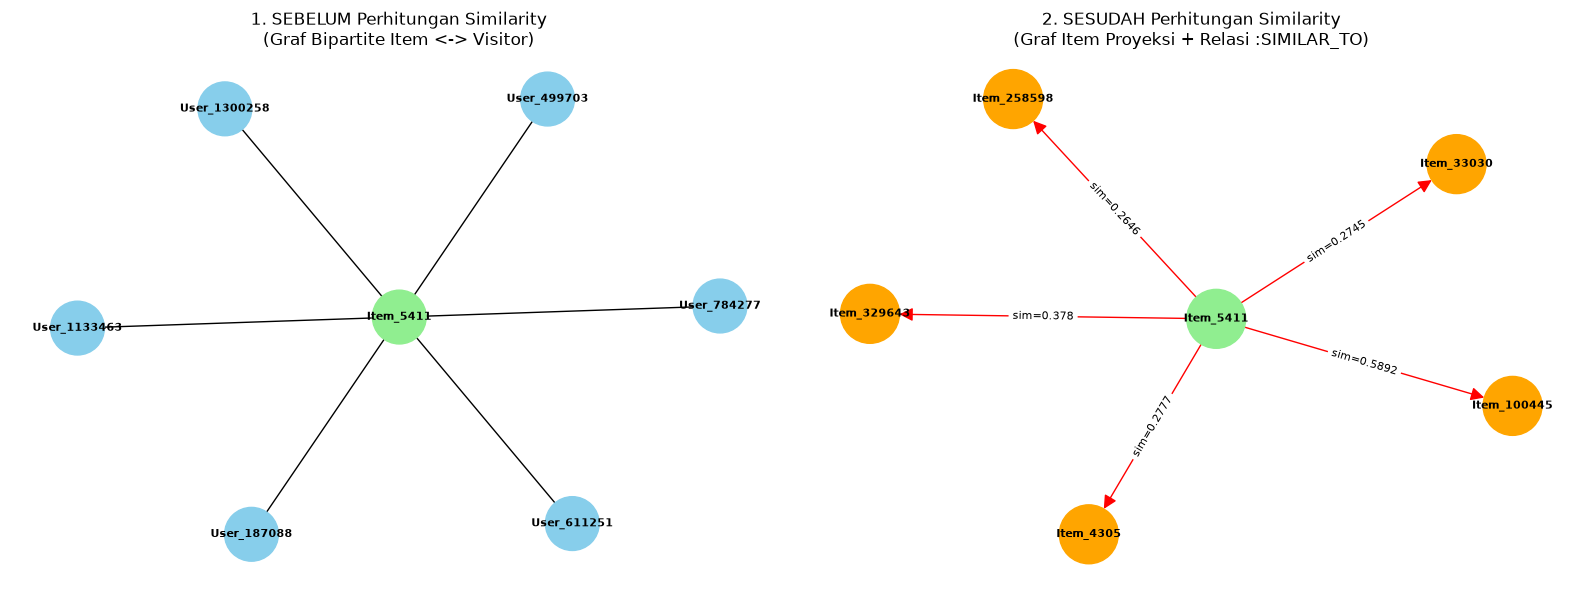

In [29]:
import matplotlib.pyplot as plt
import networkx as nx

target_item_id = 5411  # item acuan pakai di poin 7

# a. graf sebelum (murni bipartite item <-> visitor di P1)
cypher_before = f"""
MATCH (i1:Item {{itemId: {target_item_id}}})<-[r1]-(v:Visitor)
WHERE r1.timestamp >= {p1_start_ts} AND r1.timestamp <= {p1_end_ts}
RETURN i1.itemId AS Item_Acuan, v.visitorId AS Visitor_ID
LIMIT 10
"""

with driver.session() as session:
    data_before = [r.data() for r in session.run(cypher_before)]

G_before = nx.Graph()
G_before.add_node(f"Item_{target_item_id}", bipartite=0, color='lightgreen')

for row in data_before:
    v_node = f"User_{row['Visitor_ID']}"
    G_before.add_node(v_node, bipartite=1, color='skyblue')
    G_before.add_edge(f"Item_{target_item_id}", v_node)

# b. graf sesudah (ditambah relasi :SIMILAR_TO antar item)
cypher_after = f"""
MATCH (i1:Item {{itemId: {target_item_id}}})-[s:SIMILAR_TO]->(i2:Item)
RETURN i1.itemId AS From_Item, i2.itemId AS To_Item, s.score AS Score
"""

with driver.session() as session:
    data_after = [r.data() for r in session.run(cypher_after)]

G_after = nx.DiGraph()  
G_after.add_node(f"Item_{target_item_id}", color='lightgreen')

for row in data_after:
    to_node = f"Item_{row['To_Item']}"
    G_after.add_node(to_node, color='orange')
    G_after.add_edge(f"Item_{target_item_id}", to_node, weight=row['Score'])

# c. before after
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# before
pos_b = nx.spring_layout(G_before, seed=42)
colors_b = [G_before.nodes[n].get('color', 'gray') for n in G_before.nodes()]
nx.draw(G_before, pos_b, ax=axes[0], with_labels=True, node_color=colors_b, node_size=1500, font_size=8, font_weight='bold')
axes[0].set_title("1. SEBELUM Perhitungan Similarity\n(Graf Bipartite Item <-> Visitor)")

# after
pos_a = nx.spring_layout(G_after, seed=42)
colors_a = [G_after.nodes[n].get('color', 'gray') for n in G_after.nodes()]
nx.draw(G_after, pos_a, ax=axes[1], with_labels=True, node_color=colors_a, node_size=1800, font_size=8, font_weight='bold', edge_color='red', arrowsize=20)

# tambahkan label nilai similarity pada garis edge
edge_labels = {(u, v): f"sim={d['weight']}" for u, v, d in G_after.edges(data=True)}
nx.draw_networkx_edge_labels(G_after, pos_a, edge_labels=edge_labels, ax=axes[1], font_size=8)
axes[1].set_title("2. SESUDAH Perhitungan Similarity\n(Graf Item Proyeksi + Relasi :SIMILAR_TO)")

plt.tight_layout()
plt.show()

# Analytics

In [30]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# proses acak terkontrol (reproducible)
# menggunakan np.random.seed agar visitor acak yang terpilih selalu sama
np.random.seed(42)  # nilai 42 menjamin hasil reproducible
random_user_idx = np.random.choice(len(unique_visitors))
selected_visitor_id = idx_to_visitor[random_user_idx]

print(f"SELECTION OF RANDOM VISITOR (REPRODUCIBLE)")
print(f"Random Seed : 42")
print(f"Selected Visitor ID : {selected_visitor_id} (Index: {random_user_idx})\n")

# (a) SKRIP PYTHON UNTUK K-NEAREST NEIGHBORS (k-NN, K=5)
def get_knn_and_recommendations(target_visitor_id, k_neighbors=5, top_n_items=3):
    target_idx = visitor_to_idx[target_visitor_id]
    target_vector = vsm_sparse[target_idx]
    
    # hitung cosine similarity ke seluruh user
    sim_scores = cosine_similarity(target_vector, vsm_sparse).flatten()
    
    # abaikan diri sendiri
    sim_scores[target_idx] = -1
    
    # ambil indeks k tetangga terdekat (k-NN) dengan similarity tertinggi
    knn_indices = np.argsort(sim_scores)[::-1][:k_neighbors]
    
    knn_list = []
    for rank, idx in enumerate(knn_indices, 1):
        knn_list.append({
            "Rank": rank,
            "Neighbor_Visitor_ID": idx_to_visitor[idx],
            "Similarity_Score": round(float(sim_scores[idx]), 4)
        })
    df_knn = pd.DataFrame(knn_list)
    
    # (b) penentuan 3 item rekomendasi dari K=5 tetangga
    target_items = set(vsm_sparse[target_idx].indices)
    
    # kumpulkan semua item yang pernah diakses oleh 5 tetangga terdekat
    candidate_items = {}
    for idx in knn_indices:
        neighbor_sim = sim_scores[idx]
        neighbor_items = vsm_sparse[idx].indices
        for item_idx in neighbor_items:
            if item_idx not in target_items:  # Filter item yang belum pernah diakses target
                candidate_items[item_idx] = candidate_items.get(item_idx, 0) + neighbor_sim
                
    # urutkan candidate items berdasarkan total akumulasi skor similarity
    sorted_candidate_indices = sorted(candidate_items.items(), key=lambda x: x[1], reverse=True)[:top_n_items]
    
    recommended_item_ids = [idx_to_item[i_idx] for i_idx, score in sorted_candidate_indices]
    
    return df_knn, recommended_item_ids

# eksekusi k-NN dan rekomendasi 3 item
df_knn_result, top_3_items = get_knn_and_recommendations(selected_visitor_id, k_neighbors=5, top_n_items=3)

print("(a) 5 NEAREST NEIGHBORS (k=5)")
print(df_knn_result)

print("\n(b) 3 ITEM YANG RELEVAN DI IKLANKAN")
print(f"Top 3 Recommended Item IDs untuk Visitor {selected_visitor_id}:")
for rank, item_id in enumerate(top_3_items, 1):
    print(f"{rank}. Item ID: {item_id}")

SELECTION OF RANDOM VISITOR (REPRODUCIBLE)
Random Seed : 42
Selected Visitor ID : 94004 (Index: 121958)

(a) 5 NEAREST NEIGHBORS (k=5)
   Rank  Neighbor_Visitor_ID  Similarity_Score
0     1                84497            1.0000
1     2               332434            0.7071
2     3               830199            0.0000
3     4              1379473            0.0000
4     5              1011256            0.0000

(b) 3 ITEM YANG RELEVAN DI IKLANKAN
Top 3 Recommended Item IDs untuk Visitor 94004:
1. Item ID: 97932
2. Item ID: 254580
3. Item ID: 31190


In [31]:
import numpy as np
import pandas as pd

target_eval_visitor = 94004  # visitor acuan dari soal 2.2 Poin 1

# 1. ambil kategori/daftar item aktual yang diinteraksi visitor 94004 di P2
cypher_eval_user = f"""
MATCH (v:Visitor {{visitorId: {target_eval_visitor}}})-[r]->(i:Item)
WHERE r.timestamp >= {p2_start_ts} AND r.timestamp <= {p2_end_ts}
RETURN DISTINCT i.itemId AS actual_item
"""

with driver.session() as session:
    actual_items_p2 = set([r['actual_item'] for r in session.run(cypher_eval_user)])

# ambil top-5 item rekomendasi (K=5) dari fungsi k-NN
_, top_5_rec_items = get_knn_and_recommendations(target_eval_visitor, k_neighbors=5, top_n_items=5)

# 2. hitung metrik Hit@5 dan NDCG@5
# relevansi biner (1 jika item rekomendasi ada di P2, 0 jika tidak)
relevance = [1 if item in actual_items_p2 else 0 for item in top_5_rec_items]

# (a) Hit@5 
hit_at_5 = 1.0 if sum(relevance) > 0 else 0.0

# (b) NDCG@5 
def calculate_ndcg(rel_list, k=5):
    rel_list = rel_list[:k]
    if not rel_list or sum(rel_list) == 0:
        return 0.0
    
    # DCG (discounted cumulative gain)
    dcg = sum([r / np.log2(idx + 2) for idx, r in enumerate(rel_list)])
    
    # IDCG (ideal DCG - urutan ideal di mana semua item relevan di posisi teratas)
    ideal_rel = sorted(rel_list, reverse=True)
    idcg = sum([r / np.log2(idx + 2) for idx, r in enumerate(ideal_rel)])
    
    return dcg / idcg if idcg > 0 else 0.0

ndcg_at_5 = calculate_ndcg(relevance, k=5)

print(f"HASIL EVALUASI REKOMENDASI UNTUK VISITOR {target_eval_visitor}")
print(f"Item Aktual di P2 (Ground Truth): {list(actual_items_p2) if actual_items_p2 else 'Tidak ada transaksi di P2'}")
print(f"Top-5 Item Rekomendasi (P1): {top_5_rec_items}")
print(f"Vektor Relevansi (Peringkat 1-5): {relevance}")
print(f"--------------------------------------------------")
print(f"(a) Hit@5  : {hit_at_5}")
print(f"(b) NDCG@5 : {ndcg_at_5:.4f}")

HASIL EVALUASI REKOMENDASI UNTUK VISITOR 94004
Item Aktual di P2 (Ground Truth): [156727]
Top-5 Item Rekomendasi (P1): [np.int64(97932), np.int64(254580), np.int64(31190), np.int64(328868)]
Vektor Relevansi (Peringkat 1-5): [0, 0, 0, 0]
--------------------------------------------------
(a) Hit@5  : 0.0
(b) NDCG@5 : 0.0000


(a) Hit@5  : 0.0

menunjukkan bahwa 5 item teratas yang direkomendasikan berdasarkan k-NN periode P1 tidak diinteraksi oleh visitor 94004 pada periode P2.

(b) NDCG@5 : 0.0000

karena tidak ada item rekomendasi yang relevan (rel_i = 0 untuk seluruh peringkat 1-5), maka akumulasi bobot gain (DCG) bernilai 0